# Tutorial 3: Modern ocean-island basalts

This tutorial reproduces the comparison in the meltinv paper: we invert **1,801 modern ocean-island basalts from 112 locations** and compare the results with independent estimates of lithospheric thickness (seismology), melting pressure (thermobarometry) and plume excess temperature (published estimates).

It has two parts:

- **Part A, hands-on (about a minute):** you run meltinv yourself on five locations that span thin to thick lithosphere.
- **Part B, the full dataset:** inverting all 1,801 samples takes about 10 minutes, so the results are stored with the tutorial and loaded here. Set `RUN_FULL_ANALYSIS = True` below to recompute them yourself.

Part B ends with the paper's comparison figure, with and without the T–P (pyroxenite) correction.

### Two kinds of cell

| Cell starts with | What it does | Needed for your own analysis? |
|---|---|---|
| `# ▶ meltinv` | Runs meltinv, or prepares its input | **Yes**. These are the only steps you need |
| `# (optional)` | Reads the result files or makes plots, to show what meltinv did | No. Only for looking at the results |

For the whole dataset, the analysis is a single line:

```python
import meltinv

meltinv.invert("modern_OIB.xlsx", depleted_locations=["Iceland", "Galapagos"], correction=True)
```

If you have not done so yet, start with [Tutorial 2](02_python_quick_start.ipynb), which explains the inputs, outputs and figures in more detail.

## 0. Setup

In [1]:
# ▶ meltinv: import meltinv, choose the settings and work in a folder for the outputs
import os
import shutil
import sys
from pathlib import Path

try:
    import meltinv
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "meltinv is not installed in the Python that runs this notebook.\n"
        "Fix: in JupyterLab choose Kernel > Change Kernel > 'Python (meltinv)', or close JupyterLab and start it\n"
        "again with the Python where meltinv is installed, e.g. from the tutorials folder:\n"
        "    ../venv/bin/python -m jupyterlab\n"
        "(see tutorials/README.md)") from None

RUN_FULL_ANALYSIS = False                 # True: recompute the full dataset (about 10 minutes)
DEPLETED = ["Iceland", "Galapagos"]       # locations whose source may be more depleted than primitive mantle

# meltinv writes its results to the current folder; this notebook works in tutorials/output/03_modern_OIB/
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tutorials" / "data").exists())
data = repo / "tutorials" / "data"
work = repo / "tutorials" / "output" / "03_modern_OIB"
work.mkdir(parents=True, exist_ok=True)
os.chdir(work)
print(f"meltinv {meltinv.__version__}, Python {sys.version.split()[0]}")

meltinv 0.1.0, Python 3.11.15


In [2]:
# (optional) tools for reading the result files and making plots
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

sys.path.insert(0, str(repo / "tutorials"))
import paper_figures as pf                # the paper's comparison figure (tutorials/paper_figures.py)

MISFIT_CUTOFF = 0.06                      # keep locations whose RMS misfit (normalised by N - 3) is below this
REE = ['La', 'Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu']


def show_log(captured, starts=("Skipping", "Results saved")):
    # Print only the useful lines of meltinv's progress log (hidden with %%capture)
    for line in captured.stdout.splitlines():
        if line.startswith(starts):
            print(line.replace(str(Path.cwd()) + "/", ""))
    for line in captured.stderr.splitlines():
        if "RuntimeWarning:" in line:
            print("Warning:", line.split("RuntimeWarning:", 1)[1].strip())


def show_png(path, width=850):
    # Display a saved figure, downsized so the notebook stays small
    img = PILImage.open(path)
    img.thumbnail((1300, 1300))
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    display(Image(data=buf.getvalue(), width=width))

## 1. The dataset

`modern_OIB.xlsx` is a compilation from the literature: the original publication of every sample is given in its `reference` and `citations` columns. Each row is one sample, with major elements, the 14 REE and, in the `thickness` column, a seismic estimate of the lithospheric thickness beneath that location.

A **location** is one volcano or island, such as `Azores (Pico)`. Locations belong to a **province**, the part of the name before the brackets (`Azores`), which is how the paper figure groups them. The cells in this section only look at the file.

In [3]:
# (optional) read the dataset and summarise it by province
oib = pd.read_excel(data / "modern_OIB.xlsx")
oib["province"] = oib.location.apply(pf.province)
print(f"{len(oib)} samples, {oib.location.nunique()} locations, {oib.province.nunique()} provinces, "
      f"from {oib.reference.nunique()} publications")

(oib.groupby("province")
    .agg(locations=("location", "nunique"), samples=("location", "size"), seismic_thickness_km=("thickness", "mean"))
    .sort_values("seismic_thickness_km").round(1))

1801 samples, 112 locations, 33 provinces, from 231 publications


,locations,samples,seismic_thickness_km
province,,,
Galapagos Islands,13,150,44.2
Easter,2,19,45.5
Iceland,5,344,50.6
Ascension,1,1,54.3
Louisville Seamount,1,4,55.0
Jan Mayen,1,9,57.6
Tristan Da Cunha,1,5,58.3
Ross,1,5,59.4
Azores,10,95,59.5


Most samples have all 14 REE; a few have only 6–8, which is still enough (meltinv needs at least 6):

In [4]:
# (optional) count the usable REE values of each sample
usable = oib[REE].apply(pd.to_numeric, errors="coerce").gt(0).sum(axis=1)
usable.value_counts().sort_index().rename_axis("usable REE per sample").rename("samples").to_frame().T

usable REE per sample,6,7,8,9,10,11,12,13,14
samples,18,20,145,49,25,14,40,55,1435


# Part A: hands-on with five locations

## 2. Make a small input file

These five locations span seismic lithospheric thicknesses from about 45 to 90 km. Isabela, in the Galápagos, is a location whose source may be depleted, so it also shows the `depleted_locations` option. With your own data you would start directly from your own file.

In [5]:
# ▶ meltinv input: a smaller file with five locations (with your own data, use your own file instead)
FIVE = ["Galapagos Islands (Isabela)", "Azores (Pico)", "Juan Fernandez Islands (Alexander Selkirk)",
        "Samoan Islands (Tutuila)", "Canary Islands (Tenerife)"]
all_samples = pd.read_excel(data / "modern_OIB.xlsx")
all_samples[all_samples.location.isin(FIVE)].to_excel("five_locations.xlsx", index=False)

In [6]:
# (optional) how many samples, and how thick is the lithosphere, at each location?
five_input = pd.read_excel("five_locations.xlsx")
(five_input.groupby("location").agg(samples=("location", "size"), seismic_thickness_km=("thickness", "mean"))
           .sort_values("seismic_thickness_km").round(1))

,samples,seismic_thickness_km
location,,
Galapagos Islands (Isabela),10,44.6
Azores (Pico),13,52.8
Juan Fernandez Islands (Alexander Selkirk),9,64.1
Samoan Islands (Tutuila),16,81.7
Canary Islands (Tenerife),10,89.5


## 3. Correct and invert

One call does both steps: `correction=True` first adds olivine back to each sample until it is in equilibrium with mantle olivine (Fo90), then inverts every sample.

`depleted_locations=DEPLETED` widens the enrichment search for any location whose name contains `"Iceland"` or `"Galapagos"`: as well as adding up to 15% basalt to primitive mantle, meltinv also tries mixing it with up to 100% depleted mantle. These appear as negative enrichment values.

In [7]:
%%capture five_log
# ▶ meltinv: olivine correction and inversion in one call
# (%%capture only hides the long progress log; it is not needed in your own scripts)
meltinv.invert("five_locations.xlsx", depleted_locations=DEPLETED, correction=True)

In [8]:
# (optional) show the useful lines of the hidden log
show_log(five_log)

Results saved to: inversion_results/five_locations_corrected.xlsx
Skipping Azores (Pico) sample 1: 0 usable REE value(s), at least 6 needed.
Skipping Azores (Pico) sample 11: 0 usable REE value(s), at least 6 needed.
Results saved to: inversion_results/five_locations_sample_inversion_log10.xlsx
Results saved to: inversion_results/five_locations_sample_inversion_summary_log10.xlsx


Two Azores (Pico) samples could not be corrected for olivine fractionation, so their REE were set to missing and they were skipped (section 7 explains why this happens). The other 56 samples were inverted.

**That is the whole analysis for these five locations.** The cells below only read the results.

The location summary, ordered by seismic thickness. `depth_mean_cali` is the inverted lithospheric thickness and `litho_thickness_ref` the seismic one:

In [9]:
# (optional) read the location summary
five_summary = pd.read_excel("inversion_results/five_locations_sample_inversion_summary_log10.xlsx")
cols = ["location", "count", "T_mean_cali", "depth_mean_cali", "litho_thickness_ref", "basalt_percentage", "misfit_value"]
five_summary.sort_values("litho_thickness_ref")[cols].round(2)

,location,count,T_mean_cali,depth_mean_cali,litho_thickness_ref,basalt_percentage,misfit_value
2,Galapagos Islands (Isabela),10,113.49,40.06,44.65,-10.30,0.01
0,Azores (Pico),11,69.39,52.60,52.78,3.32,0.03
3,Juan Fernandez Islands (Alexander Selkirk),9,132.74,63.79,64.06,5.55,0.02
4,Samoan Islands (Tutuila),16,113.18,79.45,81.74,9.76,0.01
1,Canary Islands (Tenerife),10,113.92,82.38,89.49,9.25,0.03


## 4. Look at one location

The group comparison figure shows how the individual samples at Tutuila (Samoa) spread in temperature, thickness and enrichment. Points are coloured by misfit; the dashed lines and grey bands are the misfit-weighted mean ± 1 standard deviation used in the summary above.

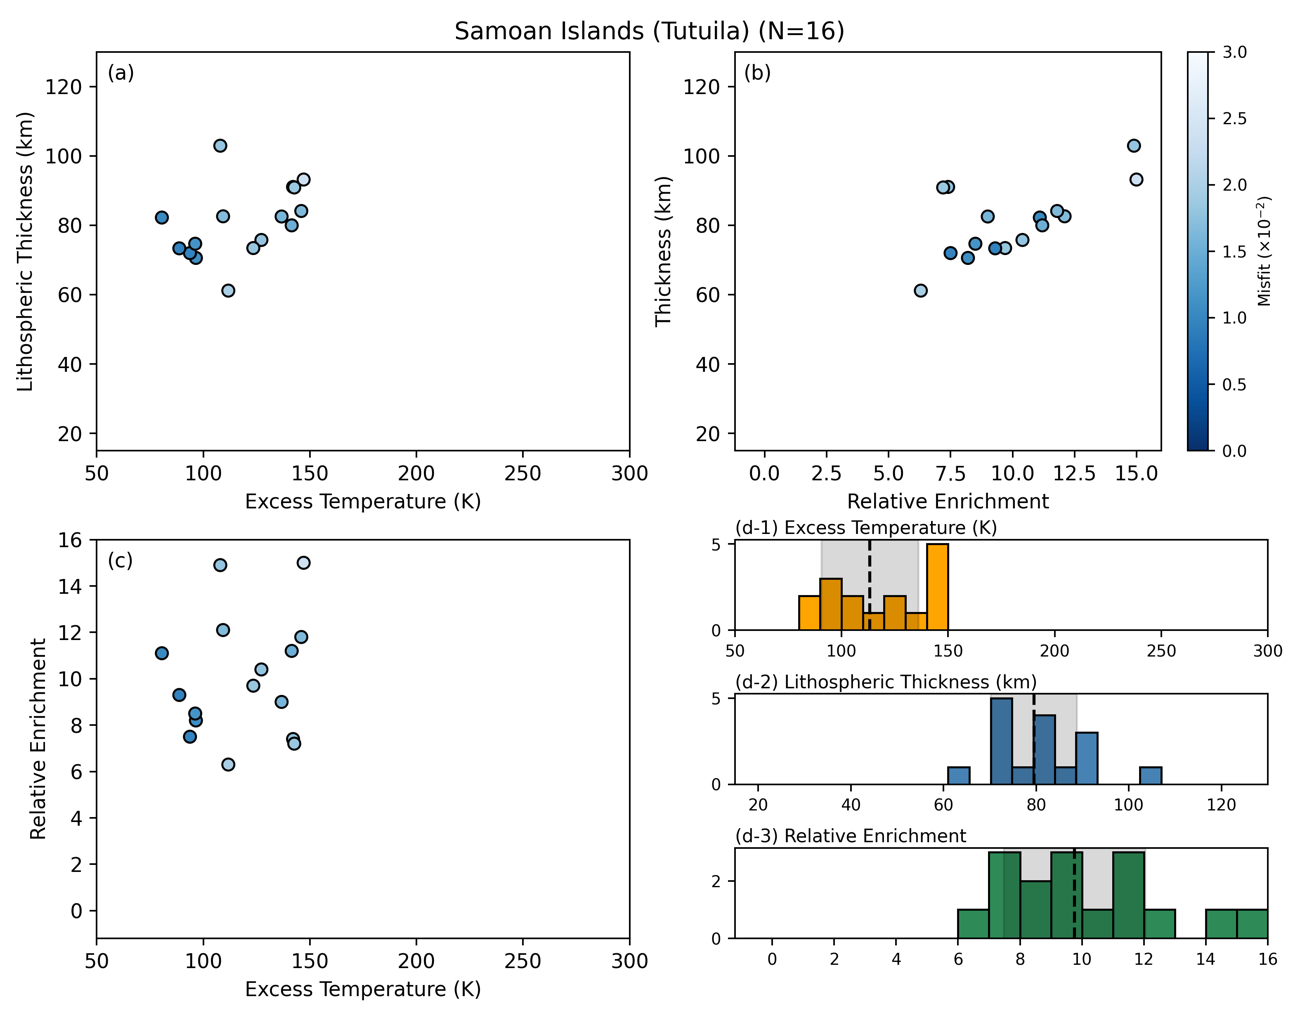

In [10]:
# (optional) show the saved group comparison figure for Tutuila
show_png(next(Path("inversion_figures").glob("group_comparison_Samoan Islands (Tutuila)_N*.png")))

## 5. Compare with seismic thickness

For these five locations, the inverted thickness follows the seismic estimate. The T–P correction moves each point up by an amount that depends on its inferred enrichment.

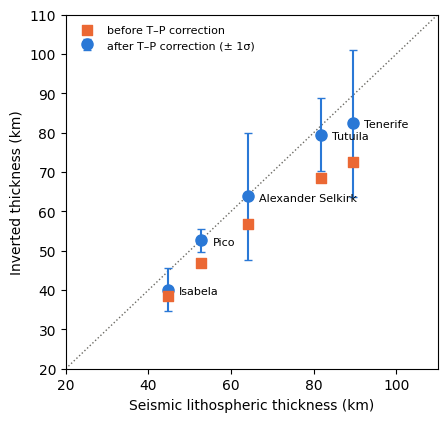

In [11]:
# (optional) plot inverted against seismic lithospheric thickness
s = five_summary.sort_values("litho_thickness_ref")
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([20, 110], [20, 110], ":", color="#6b6a64", lw=1)
ax.errorbar(s.litho_thickness_ref, s.depth_mean_cali,
            yerr=[s.depth_mean_cali - s.depth_mean_cali_err_minus, s.depth_mean_cali_err_plus - s.depth_mean_cali],
            fmt="o", ms=8, color="#2a78d6", capsize=3, label="after T–P correction (± 1σ)")
ax.scatter(s.litho_thickness_ref, s.depth_mean, s=50, marker="s", color="#eb6834", zorder=3,
           label="before T–P correction")
for _, r in s.iterrows():
    ax.annotate(r.location.split("(")[-1].rstrip(")"), (r.litho_thickness_ref, r.depth_mean_cali),
                textcoords="offset points", xytext=(8, -3), fontsize=8)
ax.set(xlabel="Seismic lithospheric thickness (km)", ylabel="Inverted thickness (km)", xlim=(20, 110), ylim=(20, 110))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

# Part B: the full dataset

## 6. Recompute (optional) and load the full results

The full results were produced by exactly the meltinv call below and are stored in `tutorials/data/modern_OIB_precomputed/`. With `RUN_FULL_ANALYSIS = False` (the default) the call is skipped and the stored results are read. Set it to `True` in the setup cell to recompute them (about 10 minutes); they are then read from this notebook's working folder instead.

In [12]:
%%capture full_log
# ▶ meltinv: the full dataset (runs only if RUN_FULL_ANALYSIS = True)
if RUN_FULL_ANALYSIS:
    shutil.copy(data / "modern_OIB.xlsx", "modern_OIB.xlsx")
    meltinv.invert("modern_OIB.xlsx", depleted_locations=DEPLETED, correction=True)

In [13]:
# (optional) read the full results: the new ones, or the stored ones
results = Path("inversion_results") if RUN_FULL_ANALYSIS else data / "modern_OIB_precomputed"
corrected = pd.read_excel(results / "modern_OIB_corrected.xlsx")
samples = pd.read_excel(results / "modern_OIB_sample_inversion_log10.xlsx")
summary = pd.read_excel(results / "modern_OIB_sample_inversion_summary_log10.xlsx")
print(f"{'Recomputed' if RUN_FULL_ANALYSIS else 'Stored'} results: {len(corrected)} samples corrected, "
      f"{len(samples)} inverted, {len(summary)} locations summarised")

Stored results: 1801 samples corrected, 1652 inverted, 111 locations summarised


## 7. Which samples could not be corrected?

The olivine correction fails for some samples. Comparing their MgO with the rest shows why:

Correction succeeded for 1652 samples and failed for 149
Median MgO: 10.0 wt% (succeeded) vs 15.7 wt% (failed)


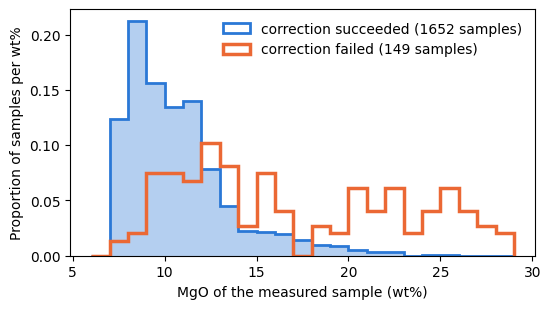

,failed samples
location,
Hawaiian Islands (Mauna Kea),29
Mascarene Islands (Reunion),13
Iceland (NNVZ),10
Hawaiian Islands (East Molokai),9
Hawaiian Islands (Mauna Loa),9
Hawaiian Islands (Kilauea),9


In [14]:
# (optional) compare the MgO of samples whose correction succeeded or failed
mgo = pd.to_numeric(oib.MgO, errors="coerce")
ok = corrected.correction_success.to_numpy()
print(f"Correction succeeded for {ok.sum()} samples and failed for {(~ok).sum()}")
print(f"Median MgO: {mgo[ok].median():.1f} wt% (succeeded) vs {mgo[~ok].median():.1f} wt% (failed)")

# Proportions, so the 149 failed samples can be compared with the 1,652 successful ones
fig, ax = plt.subplots(figsize=(6, 3.2))
bins = np.arange(6, 30, 1)
ax.hist(mgo[ok], bins=bins, density=True, histtype="stepfilled", color="#2a78d6", alpha=0.35)
ax.hist(mgo[ok], bins=bins, density=True, histtype="step", color="#2a78d6", lw=2,
        label=f"correction succeeded ({ok.sum()} samples)")
ax.hist(mgo[~ok], bins=bins, density=True, histtype="step", color="#eb6834", lw=2.5,
        label=f"correction failed ({(~ok).sum()} samples)")
ax.set(xlabel="MgO of the measured sample (wt%)", ylabel="Proportion of samples per wt%")
ax.legend(frameon=False)
plt.show()

corrected[~ok].location.value_counts().head(6).rename("failed samples").to_frame()

Most failed samples are much richer in MgO than the rest. They are already more magnesian than a melt in equilibrium with Fo90 olivine, most likely because they contain **accumulated olivine crystals**, so adding olivine cannot bring them into equilibrium. About a quarter of the failed samples have ordinary MgO contents (below 12 wt%); meltPT cannot find a solution for them for other reasons, such as unusual FeO. meltinv flags them (`correction_success = False`) and sets their REE to missing, so they are **not inverted** rather than being inverted with uncorrected compositions. Picrite-rich suites such as Mauna Kea are the most affected.

## 8. How good are the fits?

Each sample's misfit is √(Σ residual² / (N − 3)), where the residuals are the log10 differences between the observed and modelled concentrations of its N usable REE; each location summary gives the misfit-weighted average of its samples. Dividing by N − 3 rather than N makes it a little larger than the plain RMS residual, and no analytical uncertainties are used, so it is not a reduced χ². As a rough guide, a misfit of 0.06 for a sample with all 14 REE is an RMS residual of 0.06 × √(11/14) ≈ 0.053: the modelled and observed concentrations typically differ by about 10^0.053 ≈ 1.13, i.e. ~13%. We keep locations below `MISFIT_CUTOFF`:

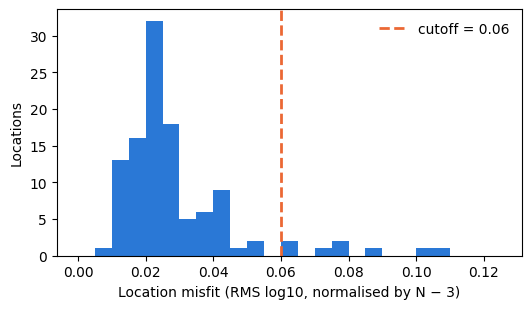

103 of 111 locations pass. Locations above the cutoff:


,location,count,misfit_value
11,Azores (D. Joao Castro Bank),1,0.060
65,Hawaiian Islands (Niihau),40,0.061
94,Ross,4,0.073
110,Tuvalu,5,0.077
44,Galapagos Islands (Darwin),4,0.078
75,Jan Mayen,4,0.087
55,Galapagos Islands (Unnamed),10,0.103
48,Galapagos Islands (Genovesa),18,0.107


In [15]:
# (optional) plot the misfit of every location and list those above the cutoff
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(summary.misfit_value, bins=np.arange(0, 0.13, 0.005), color="#2a78d6")
ax.axvline(MISFIT_CUTOFF, color="#eb6834", lw=2, ls="--", label=f"cutoff = {MISFIT_CUTOFF}")
ax.set(xlabel="Location misfit (RMS log10, normalised by N − 3)", ylabel="Locations")
ax.legend(frameon=False)
plt.show()

good = summary.misfit_value < MISFIT_CUTOFF
print(f"{good.sum()} of {len(summary)} locations pass. Locations above the cutoff:")
summary.loc[~good, ["location", "count", "misfit_value"]].sort_values("misfit_value").round(3)

## 9. Samples at the edge of the search grid

The enrichment search runs from 0 to 15% basalt (or down to −100%, i.e. 100% depleted mantle, for the `DEPLETED` locations). A best fit exactly on one of these limits may mean the true value lies outside the searched range, so those samples deserve caution:

In [16]:
# (optional) count the samples whose best-fit enrichment is at a limit of the search
at_top = np.isclose(samples.basalt_percentage, 15)
at_bottom = np.isclose(samples.basalt_percentage, -100)
print(f"{at_top.sum()} samples at +15% and {at_bottom.sum()} at -100% "
      f"({(at_top | at_bottom).mean():.0%} of all inverted samples)")
samples[at_top | at_bottom].location.value_counts().head(6).rename("samples at an enrichment limit").to_frame()

44 samples at +15% and 58 at -100% (6% of all inverted samples)


,samples at an enrichment limit
location,
Iceland (NNVZ),19
Galapagos Islands (Genovesa),14
Galapagos Islands (Unnamed),10
Canary Islands (La Palma),7
Iceland (SEVZ),7
Hawaiian Islands (Oahu A),4


## 10. Comparison with independent estimates

How well do the location summaries agree with estimates that meltinv does not use? The table compares, for the locations that pass the misfit cutoff:

- **lithospheric thickness** with the seismic estimates;
- **excess temperature** with Putirka (2008) and Bao et al. (2022), averaged by province;
- **average melting pressure** with the Plank & Forsyth (2016) thermobarometer applied to the same primary magmas.

It does so both before and after the T–P (pyroxenite) correction, which uses the inferred enrichment as a pyroxenite fraction. This is an additional physical assumption, so it is useful to show both.

In [17]:
# (optional) agreement with independent estimates, before and after the T–P correction
lit_T = pd.read_csv(data / "literature_excess_temperatures.csv")
pf16 = pd.read_csv(data / "PF16_melting_pressures.csv")
pf.agreement(summary, lit_T, pf16, misfit_cutoff=MISFIT_CUTOFF).round(2).T

,before T–P correction,after T–P correction
locations,103.00,103.00
"thickness − seismic, mean |Δ| (km)",18.06,14.02
"thickness − seismic, mean Δ (km)",-14.02,-7.68
"T − Putirka (2008), mean |Δ| (K)",39.86,55.49
"T − Bao et al. (2022), mean |Δ| (K)",48.23,50.69
"P − Plank & Forsyth (2016), mean |Δ| (GPa)",0.67,0.70


The T–P correction brings the lithospheric thickness much closer to the seismic estimates, while the agreement with the published excess temperatures becomes somewhat worse, especially for Putirka (2008). Both sets of temperatures are themselves model-based, so neither is a true reference.

## 11. The paper figure

Each column is one province, ordered by its mean seismic lithospheric thickness; each point is one location that passes the misfit cutoff. The figure is drawn by `tutorials/paper_figures.py`, which is not part of meltinv.

- **(a)** Inverted lithospheric thickness (blue) against the seismic estimates (grey; the light band shows the seismic uncertainty).
- **(b)** Average melting pressure (green; the band spans the minimum to maximum melting pressure) against Plank & Forsyth (2016) (orange, mean ± 1σ).
- **(c)** Excess temperature (red) against Putirka (2008) and Bao et al. (2022) (squares; the light band is the literature range ± 20 K).
- **(d)** Source enrichment, as % basalt added to primitive mantle. Depleted (negative) values are below the plotted range.

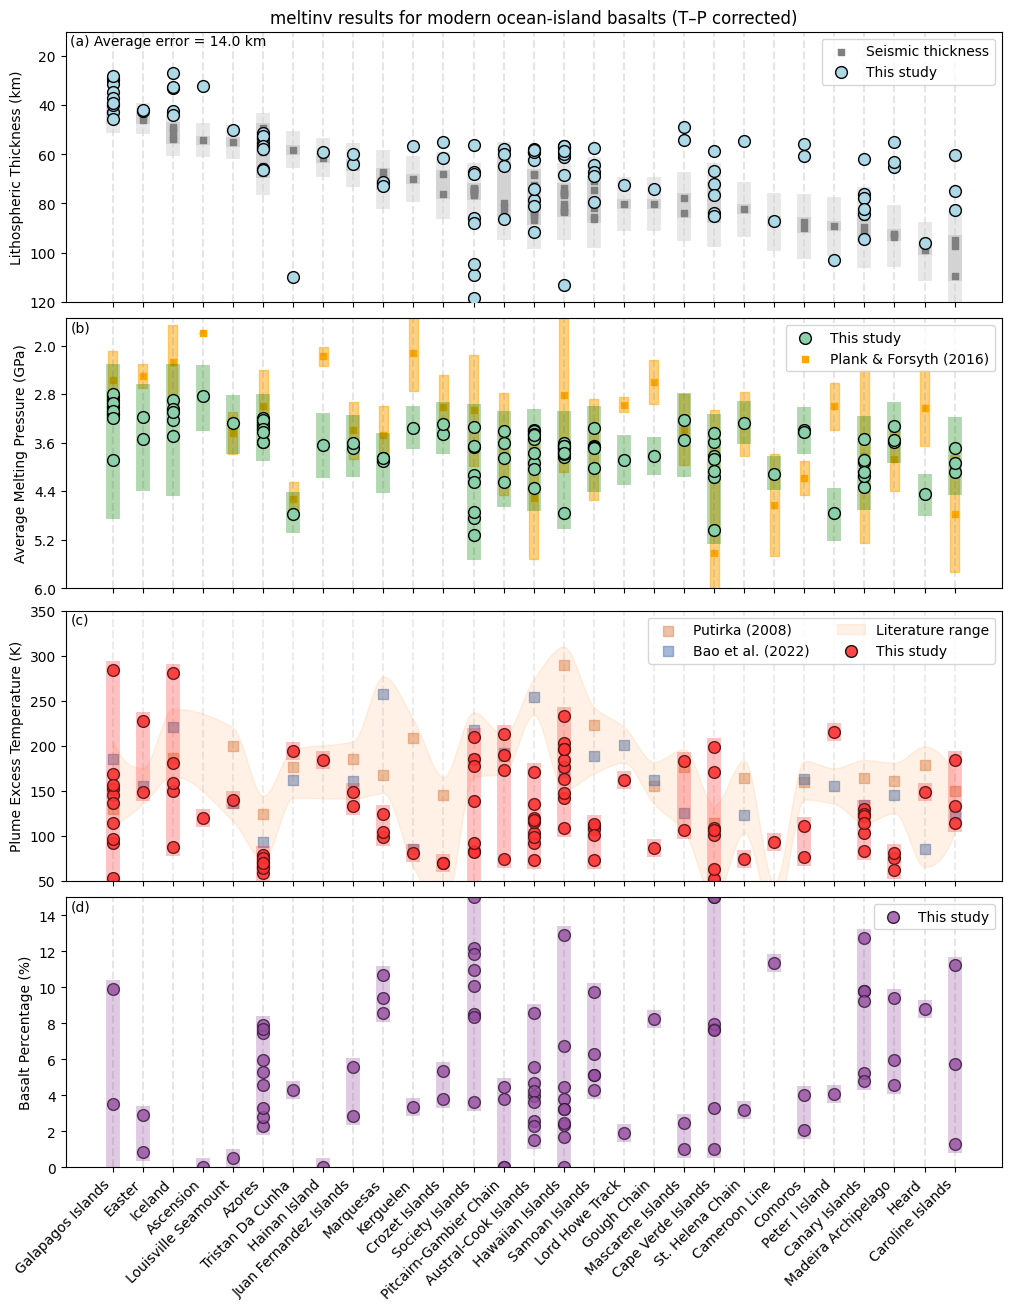

In [18]:
# (optional) the paper figure, with the T–P correction
fig = pf.comparison_figure(summary, lit_T, pf16, misfit_cutoff=MISFIT_CUTOFF, corrected=True,
                           title="meltinv results for modern ocean-island basalts (T–P corrected)")
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/modern_OIB_comparison_corrected.png", dpi=300, bbox_inches="tight")
plt.show()

The same figure **without** the T–P correction. Compare panels (a) and (c) with the figure above: without the correction, the inverted lithosphere is systematically thinner than the seismic estimates and the temperatures are higher.

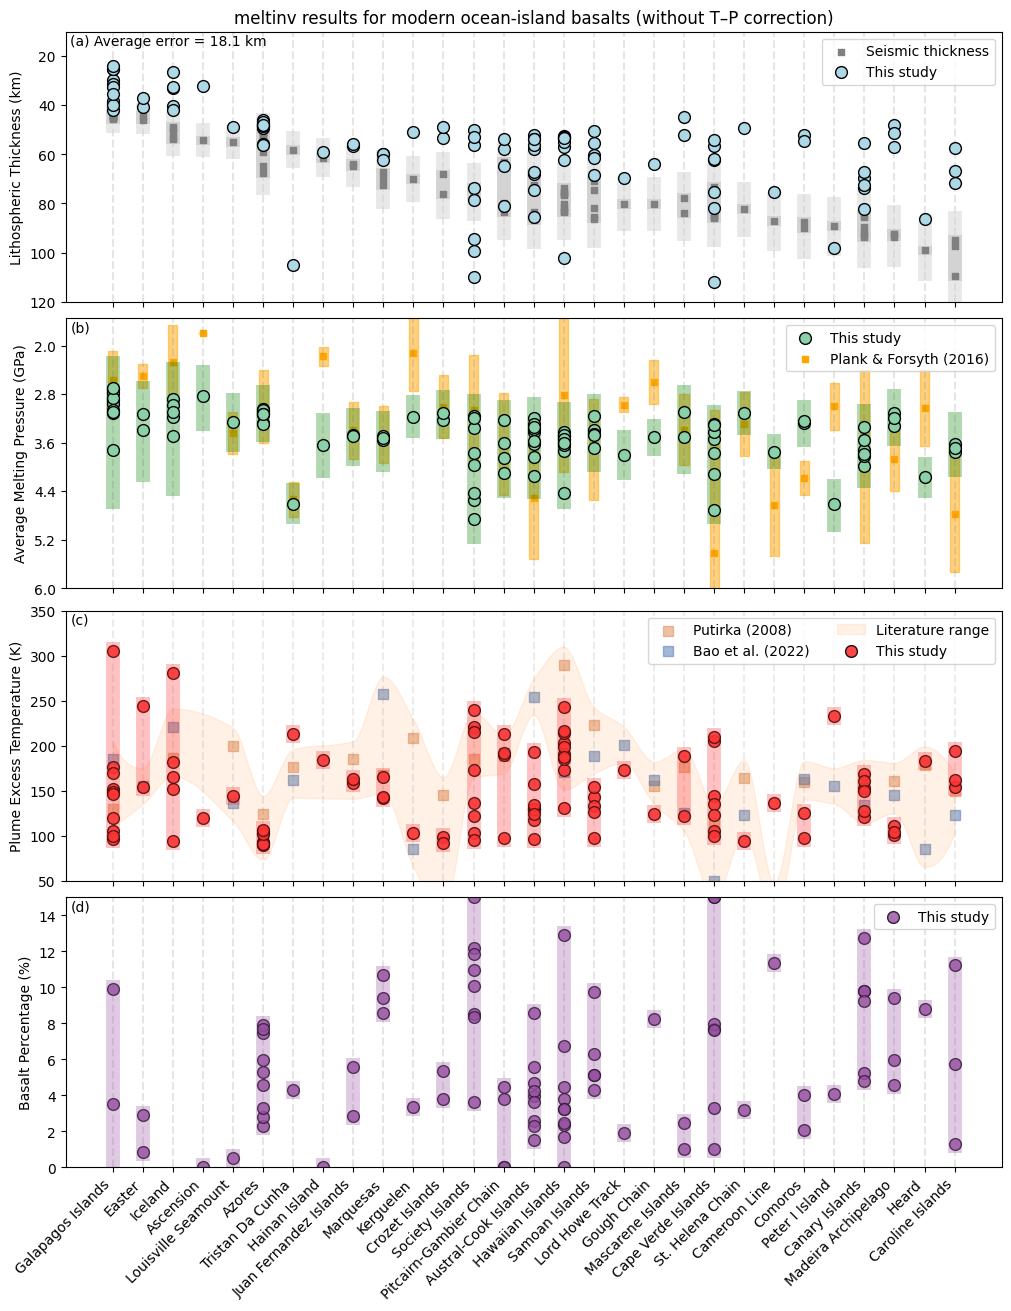

In [19]:
# (optional) the paper figure, without the T–P correction
fig = pf.comparison_figure(summary, lit_T, pf16, misfit_cutoff=MISFIT_CUTOFF, corrected=False,
                           title="meltinv results for modern ocean-island basalts (without T–P correction)")
fig.savefig("figures/modern_OIB_comparison_uncorrected.png", dpi=300, bbox_inches="tight")
plt.show()

## Summary

- The whole analysis is one `▶ meltinv` call: `meltinv.invert(..., correction=True)` corrects, inverts and summarises every location.
- Samples that cannot be corrected, typically olivine-accumulative ones, are flagged and excluded rather than inverted with uncorrected compositions.
- The misfit cutoff and the samples at the edge of the enrichment grid are the main quality checks.
- Inverted lithospheric thicknesses agree with seismic estimates to within about 14 km on average after the T–P correction; the correction itself is an assumption, so results are shown with and without it.

Both figures are saved in `tutorials/output/03_modern_OIB/figures/` at full resolution.

**References**

- Bao, X., Lithgow-Bertelloni, C. R., Jackson, M. G. & Romanowicz, B. (2022). On the relative temperatures of Earth's volcanic hotspots and mid-ocean ridges. *Science*, 375, 57–61.
- Plank, T. & Forsyth, D. W. (2016). Thermal structure and melting conditions in the mantle beneath the Basin and Range province from seismology and petrology. *Geochemistry, Geophysics, Geosystems*, 17, 1312–1338.
- Putirka, K. (2008). Excess temperatures at ocean islands: implications for mantle layering and convection. *Geology*, 36, 283–286.
- The sources of the basalt compositions are listed in the `reference` and `citations` columns of `tutorials/data/modern_OIB.xlsx`.